PLANETARY DEFENSE ANALYSIS - CLASSIFICATION

In [1]:
#Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Loading data
df = pd.read_csv('pha_dataset.csv')

C:\Users\Aishwarya\AppData\Local\Temp\ipykernel_6508\1385768572.py:2: DtypeWarning: Columns (3: pdes, 4: name, 5: prefix) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('pha_dataset.csv')


In [3]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [4]:
df.shape

(958524, 45)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 958524 entries, 0 to 958523
Data columns (total 45 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              958524 non-null  str    
 1   spkid           958524 non-null  int64  
 2   full_name       958524 non-null  str    
 3   pdes            958524 non-null  object 
 4   name            22064 non-null   str    
 5   prefix          18 non-null      str    
 6   neo             958520 non-null  str    
 7   pha             938603 non-null  str    
 8   H               952261 non-null  float64
 9   diameter        136209 non-null  float64
 10  albedo          135103 non-null  float64
 11  diameter_sigma  136081 non-null  float64
 12  orbit_id        958524 non-null  str    
 13  epoch           958524 non-null  float64
 14  epoch_mjd       958524 non-null  int64  
 15  epoch_cal       958524 non-null  float64
 16  equinox         958524 non-null  str    
 17  e               95852

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

id                     0
spkid                  0
full_name              0
pdes                   0
name              936460
prefix            958506
neo                    4
pha                19921
H                   6263
diameter          822315
albedo            823421
diameter_sigma    822443
orbit_id               0
epoch                  0
epoch_mjd              0
epoch_cal              0
equinox                0
e                      0
a                      0
q                      0
i                      0
om                     0
w                      0
ma                     1
ad                     4
n                      0
tp                     0
tp_cal                 0
per                    4
per_y                  1
moid               19921
moid_ld              127
sigma_e            19922
sigma_a            19922
sigma_q            19922
sigma_i            19922
sigma_om           19922
sigma_w            19922
sigma_ma           19922
sigma_ad           19926


In [8]:
df.columns

Index(['id', 'spkid', 'full_name', 'pdes', 'name', 'prefix', 'neo', 'pha', 'H',
       'diameter', 'albedo', 'diameter_sigma', 'orbit_id', 'epoch',
       'epoch_mjd', 'epoch_cal', 'equinox', 'e', 'a', 'q', 'i', 'om', 'w',
       'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'moid', 'moid_ld',
       'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w',
       'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'class',
       'rms'],
      dtype='str')

In [9]:
#Dropping unnecessary columns
df =df.drop(columns=['id','spkid','pdes', 'full_name','name','prefix','equinox','orbit_id']) # Identifiers
df = df.drop(columns=['sigma_e','sigma_a','sigma_q','sigma_i','sigma_om','sigma_w','sigma_ma','sigma_ad','sigma_n','sigma_tp','sigma_per']) # sigma columns

In [10]:
# Check unique values in categorical columns
categorical_cols = df.select_dtypes(include=['str']).columns

for col in categorical_cols:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique(dropna=False))
    print(df[col].value_counts(dropna=False).head(20))


neo
Unique values: 3
neo
N      935625
Y       22895
NaN         4
Name: count, dtype: int64

pha
Unique values: 3
pha
N      936537
NaN     19921
Y        2066
Name: count, dtype: int64

class
Unique values: 13
class
MBA    855954
OMB     28355
IMB     20360
MCA     18685
APO     12687
AMO      8457
TJN      8221
TNO      3468
ATE      1729
CEN       506
AST        76
IEO        22
HYA         4
Name: count, dtype: int64


In [11]:
#Checking numeric columns
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
num_cols

Index(['H', 'diameter', 'albedo', 'diameter_sigma', 'epoch', 'epoch_mjd',
       'epoch_cal', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'n', 'tp',
       'tp_cal', 'per', 'per_y', 'moid', 'moid_ld', 'rms'],
      dtype='str')

In [12]:
df.describe()

,H,diameter,albedo,diameter_sigma,epoch,epoch_mjd,epoch_cal,e,a,q,...,ma,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,rms
count,952261.000000,136209.000000,135103.000000,136081.000000,9.585240e+05,958524.000000,9.585240e+05,958524.000000,958524.000000,958524.000000,...,958523.000000,958520.000000,9.585240e+05,9.585240e+05,9.585240e+05,9.585200e+05,9.585230e+05,9.386030e+05,958397.000000,958522.000000
mean,16.906411,5.506429,0.130627,0.479184,2.458869e+06,58868.781950,2.019693e+07,0.156116,2.902143,2.394887,...,177.352582,3.455820,2.366846e-01,2.458856e+06,2.019581e+07,5.085344e+03,1.392287e+01,1.415162e+00,539.364207,0.561153
std,1.790405,9.425164,0.110323,0.782895,7.016716e+02,701.671573,1.930354e+04,0.092643,39.719503,2.139246,...,105.816844,71.769401,7.941705e-02,1.580506e+03,4.337669e+04,2.308961e+06,6.321581e+03,2.156731e+00,834.306975,2.745700
min,-1.100000,0.002500,0.001000,0.000500,2.425052e+06,25051.000000,1.927062e+07,0.000000,-14702.447872,0.070511,...,-70.703676,0.653773,1.608247e-07,2.283183e+06,1.539011e+07,1.511918e+02,0.000000e+00,4.544120e-07,0.000000,0.000000
25%,16.100000,2.780000,0.053000,0.180000,2.459000e+06,59000.000000,2.020053e+07,0.092193,2.387835,1.971401,...,83.785012,2.781603,1.894969e-01,2.458560e+06,2.019032e+07,1.347738e+03,3.689903e+00,9.797020e-01,375.394939,0.518040
50%,16.900000,3.972000,0.079000,0.332000,2.459000e+06,59000.000000,2.020053e+07,0.145002,2.646969,2.225816,...,175.641078,3.046995,2.288655e-01,2.458945e+06,2.020041e+07,1.572976e+03,4.306571e+00,1.240850e+00,477.706175,0.566280
75%,17.714000,5.765000,0.190000,0.620000,2.459000e+06,59000.000000,2.020053e+07,0.200650,3.001932,2.578315,...,269.865749,3.364793,2.671142e-01,2.459361e+06,2.021053e+07,1.899765e+03,5.201272e+00,1.593370e+00,617.324804,0.613927
max,33.200000,939.400000,1.000000,140.000000,2.459000e+06,59000.000000,2.020053e+07,1.855356,33488.895955,80.398819,...,491.618014,66972.796064,2.381082e+00,2.546362e+06,2.259081e+07,2.238462e+09,6.128574e+06,7.947660e+01,30929.908422,2686.600000


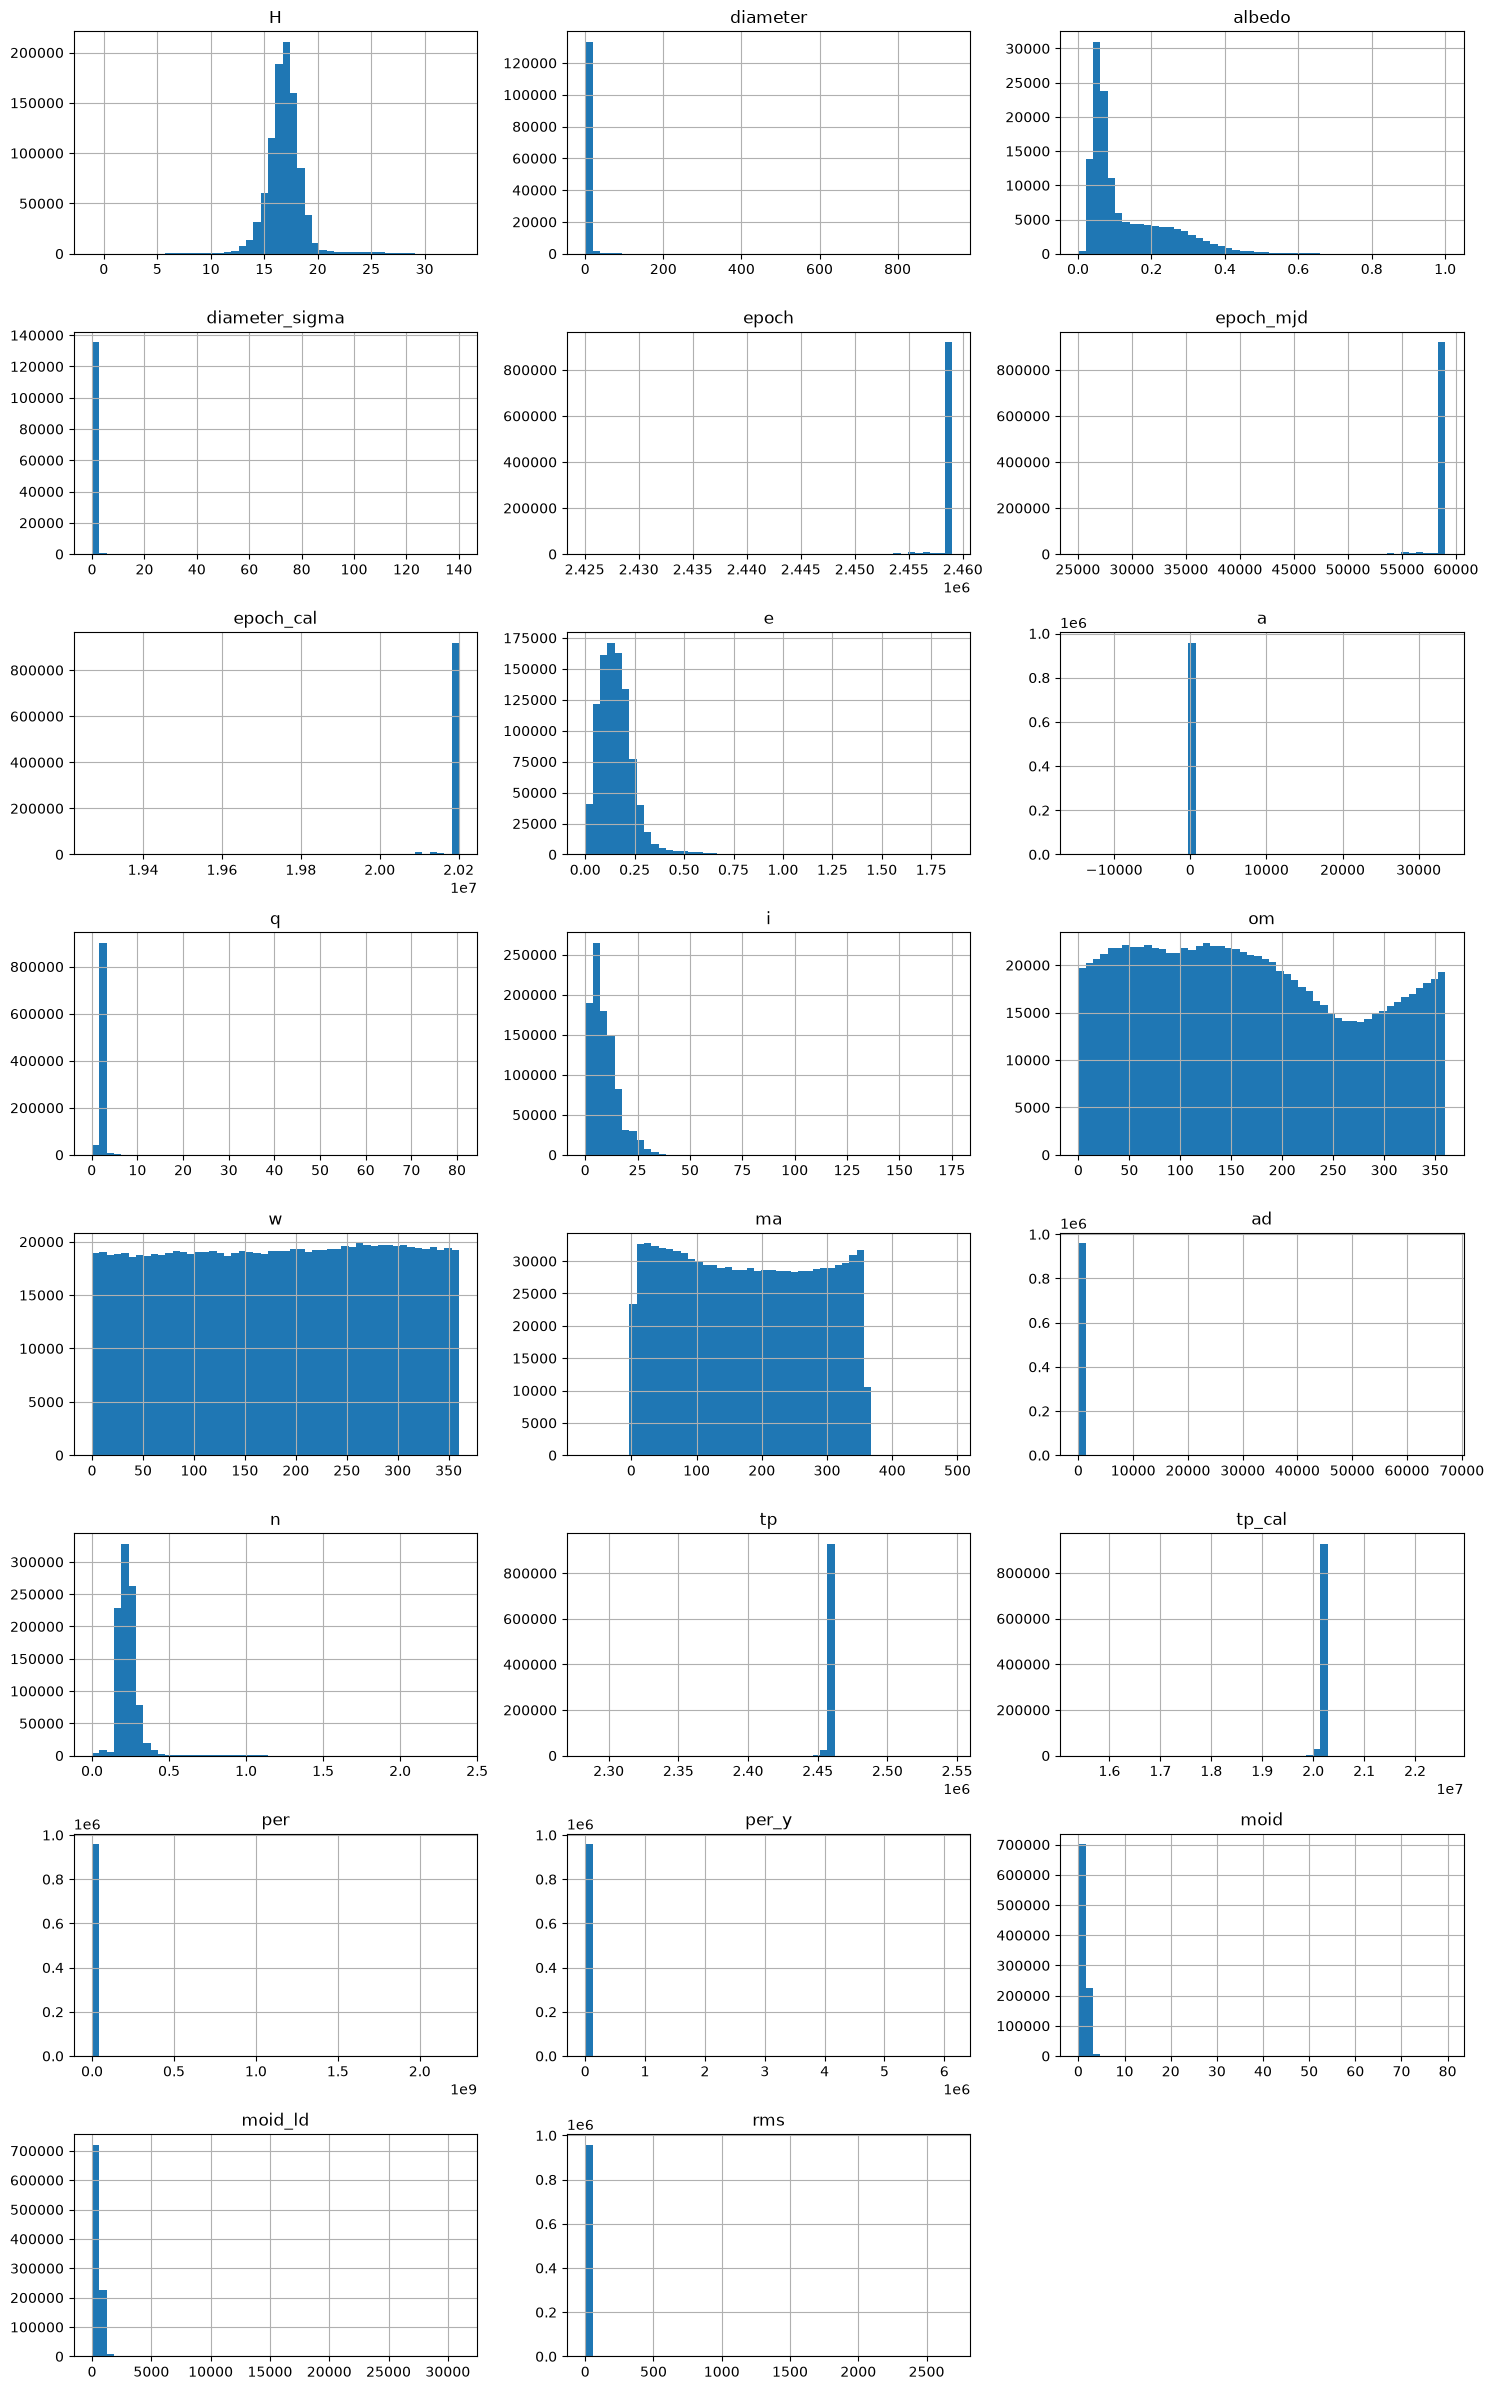

In [13]:
#check the distribution of the features
X = df[num_cols]
X.hist(bins=50,figsize=(15,24),layout=(8, 3))
plt.tight_layout()
plt.show()

Outlier Detection

In [14]:
df[num_cols].skew()

H                   0.604709
diameter           25.852418
albedo              1.683567
diameter_sigma     69.824037
epoch              -6.858078
epoch_mjd          -6.858078
epoch_cal          -6.864155
e                   1.898895
a                 577.499553
q                  15.837665
i                   2.183736
om                  0.198256
w                  -0.020330
ma                  0.040664
ad                864.424060
n                   5.623457
tp                 -4.675623
tp_cal             -4.633673
per               953.004604
per_y             953.006095
moid               15.755624
moid_ld            15.745831
rms               976.736018
dtype: float64

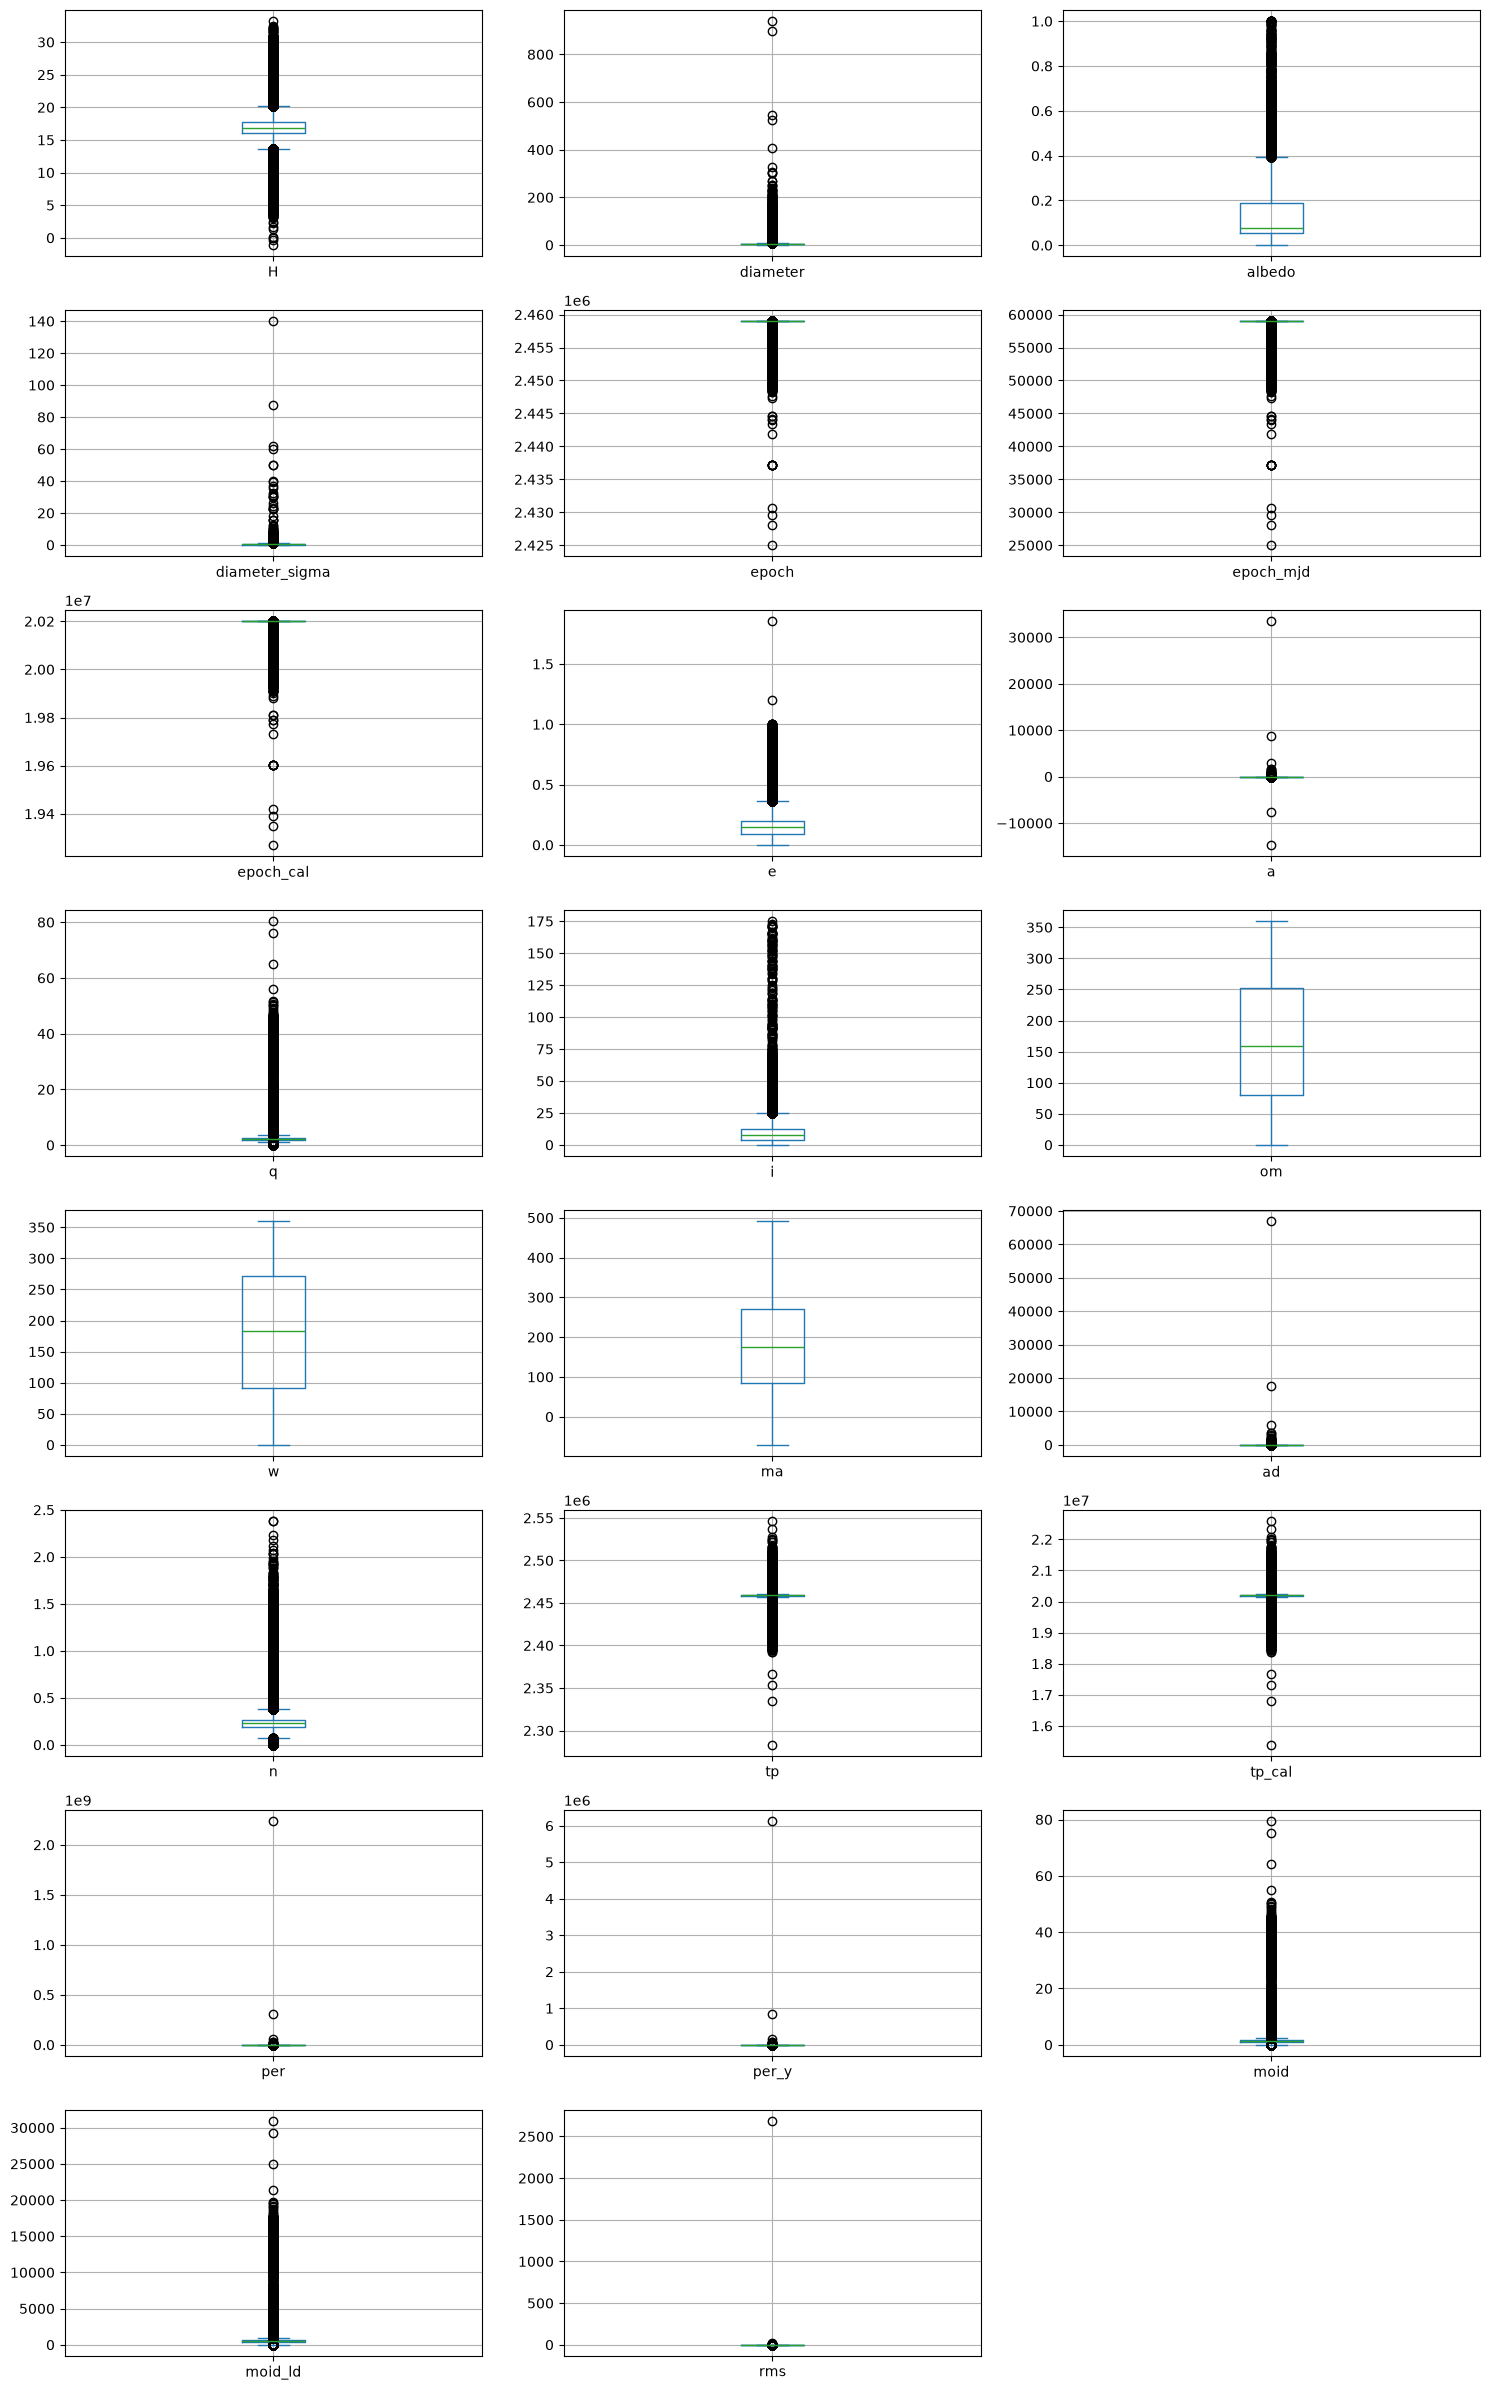

In [15]:
#Outlier detection using boxplots
X.plot(kind="box",subplots=True,layout=(8,3),figsize=(15, 24),grid=True)
plt.tight_layout()
plt.show()

In [16]:
for col in num_cols:

    Q1 = df[col].quantile(0.25)  # 25th percentile
    Q3 = df[col].quantile(0.75)  # 75th percentile
    IQR = Q3 - Q1  # Interquartile range

    # Define lower and upper bound
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap values at lower and upper bound
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

In [17]:
df[num_cols].skew()

H                -0.088597
diameter          0.958134
albedo            1.156015
diameter_sigma    1.055152
epoch             0.000000
epoch_mjd         0.000000
epoch_cal         0.000000
e                 0.592488
a                 0.168974
q                 0.023905
i                 0.937240
om                0.198256
w                -0.020330
ma                0.040664
ad                0.167453
n                 0.489694
tp               -0.499144
tp_cal           -0.303355
per               0.283125
per_y             0.283048
moid              0.041289
moid_ld          -0.216831
rms              -0.257071
dtype: float64

Handle Missing Values

In [18]:
df=df.dropna(subset='pha')

In [19]:
df.shape

(938603, 26)

In [20]:
df.isnull().sum()

neo                    4
pha                    0
H                   6262
diameter          802394
albedo            803500
diameter_sigma    802522
epoch                  0
epoch_mjd              0
epoch_cal              0
e                      0
a                      0
q                      0
i                      0
om                     0
w                      0
ma                     1
ad                     4
n                      0
tp                     0
tp_cal                 0
per                    4
per_y                  1
moid                   0
moid_ld                0
class                  0
rms                    1
dtype: int64

In [21]:
#neo imputation
df[df["neo"].isna()][["q", "neo"]]

,q,neo
741612,3.488686,NaN
929462,1.061029,NaN
946657,3.488686,NaN
950563,3.488686,NaN


In [22]:
df.groupby("neo")["q"].agg(["min", "max"])

,min,max
neo,,
N,1.300000,3.488686
Y,1.061029,1.299988


In [23]:
def fill_neo(q):
    if q < 1.3:
        return "Y"
    else:
        return "N"
missing_neo = df["neo"].isna()
df.loc[missing_neo, "neo"] = df.loc[missing_neo, "q"].apply(fill_neo)

In [24]:
df.isnull().sum()

neo                    0
pha                    0
H                   6262
diameter          802394
albedo            803500
diameter_sigma    802522
epoch                  0
epoch_mjd              0
epoch_cal              0
e                      0
a                      0
q                      0
i                      0
om                     0
w                      0
ma                     1
ad                     4
n                      0
tp                     0
tp_cal                 0
per                    4
per_y                  1
moid                   0
moid_ld                0
class                  0
rms                    1
dtype: int64

In [25]:
df= df.dropna(subset=['H']).copy()

In [26]:
df.shape

(932341, 26)

In [27]:
df=df.drop(columns=['diameter','albedo','diameter_sigma']) # Dropping columns with high missing values

In [28]:
#Imputing missing values for numerical columns
from sklearn.impute import SimpleImputer
missing_cols = ['ma', 'ad', 'per', 'per_y', 'rms']

num_imputer = SimpleImputer(strategy='median')
df[missing_cols] = num_imputer.fit_transform(df[missing_cols])

Encoding - One Hot Encoding

In [29]:
cat_cols = ['neo', 'class']
df = pd.get_dummies(df,columns=cat_cols,dtype=int)

In [30]:
#seperate features and target variable
X= df.drop("pha", axis=1)
y = df["pha"]

In [31]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)

In [32]:
df['pha'].value_counts()

pha
N    930275
Y      2066
Name: count, dtype: int64

Train Test Split

In [33]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2,random_state=42)

In [34]:
#Smote Oversampling
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

smote = SMOTE(
    sampling_strategy=1.0,
    random_state=42,
    k_neighbors=5
)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled, y_train
)

In [ ]:
# Convert X_train_resampled into a DataFrame
X_train_resampled_df = pd.DataFrame(
    X_train_resampled,
    columns=X_train.columns
)

# Convert y_train_resampled into a Series
y_train_resampled_df = pd.Series(
    y_train_resampled,
    name='pha'
)

In [36]:
print(X_train_resampled_df.shape)
print(y_train_resampled_df.shape)


print(y_train_resampled_df.value_counts())

(1488454, 35)
(1488454,)
pha
0    744227
1    744227
Name: count, dtype: int64


Model Building

In [50]:
import os
import json
import tempfile
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

In [43]:
#mlflow
import mlflow
import mlflow.sklearn
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("Planetary_Defense_Classification")

2026/10/15 20:05:59 INFO mlflow.tracking.fluent: Experiment with name 'Planetary_Defense_Classification' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1792074960013, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792074960013, lifecycle_stage='active', name='Planetary_Defense_Classification', tags={}, trace_location=None, workspace='default'>

In [44]:
models = {
    "Logistic Regression": {
        "estimator": LogisticRegression(
            max_iter=1000,
            C=1.0,
            solver="lbfgs",
            random_state=42
        ),
        "params": {
            "max_iter": 1000,
            "C": 1.0,
            "solver": "lbfgs"
        }
    },

    "Random Forest": {
        "estimator": RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=42
        ),
        "params": {
            "n_estimators": 100,
            "max_depth": "None",
            "min_samples_leaf": 2
        }
    },

    "XGBoost": {
        "estimator": XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            tree_method="hist",
            eval_metric="logloss",
            n_jobs=-1,
            random_state=42
        ),
        "params": {
            "n_estimators": 100,
            "max_depth": 6,
            "learning_rate": 0.1,
            "subsample": 0.8,
            "colsample_bytree": 0.8
        }
    },

    "KNN": {
        "estimator": KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            metric="minkowski",
            p=2,
            n_jobs=-1
        ),
        "params": {
            "n_neighbors": 5,
            "weights": "distance",
            "metric": "minkowski",
            "p": 2
        }
    }
}


Model: Logistic Regression
              precision    recall  f1-score   support

     Non-PHA       1.00      0.99      1.00    186048
         PHA       0.19      0.99      0.32       421

    accuracy                           0.99    186469
   macro avg       0.59      0.99      0.66    186469
weighted avg       1.00      0.99      0.99    186469

Confusion matrix:
[[184239   1809]
 [     4    417]]
Evaluation metrics:
{'accuracy': 0.9902772042537902, 'precision': 0.18733153638814015, 'recall': 0.9904988123515439, 'f1_score': 0.31507366830374006, 'roc_auc': 0.9982023130750822, 'average_precision': 0.583277011037785}


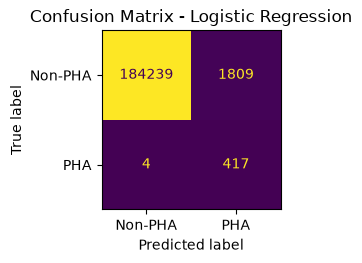

2026/10/15 21:10:02 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


MLflow run completed: Logistic Regression
🏃 View run Logistic Regression at: http://localhost:5000/#/experiments/1/runs/7985b5680c3843deb68077e12d8c4d6f
🧪 View experiment at: http://localhost:5000/#/experiments/1

Model: Random Forest
              precision    recall  f1-score   support

     Non-PHA       1.00      1.00      1.00    186048
         PHA       0.52      0.76      0.62       421

    accuracy                           1.00    186469
   macro avg       0.76      0.88      0.81    186469
weighted avg       1.00      1.00      1.00    186469

Confusion matrix:
[[185755    293]
 [   103    318]]
Evaluation metrics:
{'accuracy': 0.9978763226059023, 'precision': 0.5204582651391162, 'recall': 0.7553444180522565, 'f1_score': 0.6162790697674418, 'roc_auc': 0.9988058020120162, 'average_precision': 0.7336710150228655}


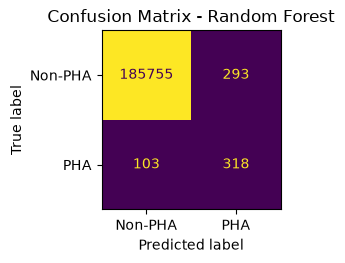

2026/10/15 21:12:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


MLflow run completed: Random Forest
🏃 View run Random Forest at: http://localhost:5000/#/experiments/1/runs/ee9add51f9cc4b3fb27431f79b393dfc
🧪 View experiment at: http://localhost:5000/#/experiments/1

Model: XGBoost
              precision    recall  f1-score   support

     Non-PHA       1.00      1.00      1.00    186048
         PHA       0.33      0.85      0.48       421

    accuracy                           1.00    186469
   macro avg       0.67      0.92      0.74    186469
weighted avg       1.00      1.00      1.00    186469

Confusion matrix:
[[185331    717]
 [    62    359]]
Evaluation metrics:
{'accuracy': 0.9958223618939341, 'precision': 0.3336431226765799, 'recall': 0.8527315914489311, 'f1_score': 0.47962591850367403, 'roc_auc': 0.9985961403876464, 'average_precision': 0.7227723421316745}


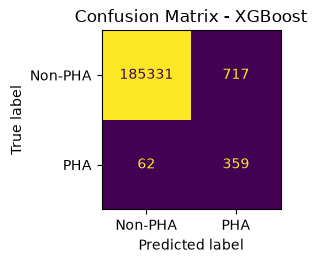

2026/10/15 21:13:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


MLflow run completed: XGBoost
🏃 View run XGBoost at: http://localhost:5000/#/experiments/1/runs/b2dff8fa8794482b9c052b37b85d47cd
🧪 View experiment at: http://localhost:5000/#/experiments/1

Model: KNN
              precision    recall  f1-score   support

     Non-PHA       1.00      0.99      1.00    186048
         PHA       0.19      0.66      0.30       421

    accuracy                           0.99    186469
   macro avg       0.59      0.83      0.65    186469
weighted avg       1.00      0.99      0.99    186469

Confusion matrix:
[[184868   1180]
 [   143    278]]
Evaluation metrics:
{'accuracy': 0.992904986887901, 'precision': 0.1906721536351166, 'recall': 0.6603325415676959, 'f1_score': 0.29590207557211284, 'roc_auc': 0.899953403846641, 'average_precision': 0.17194765756902386}


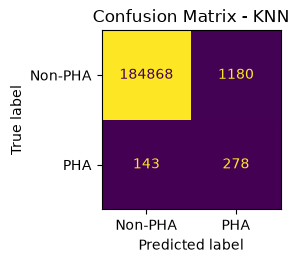

2026/10/15 21:49:52 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


MLflow run completed: KNN
🏃 View run KNN at: http://localhost:5000/#/experiments/1/runs/2ed750f6dc7c4696824fc6806801e37f
🧪 View experiment at: http://localhost:5000/#/experiments/1


In [54]:
results = []

# Begin with a moderate oversampling ratio
sampling_strategy = 0.1

for model_name, model_info in models.items():

    classifier = clone(model_info["estimator"])

    # Combine preprocessing, SMOTE, and model training
    pipeline = ImbPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("smote", SMOTE(
            sampling_strategy=sampling_strategy,
            random_state=42,
            k_neighbors=5
        )),
        ("classifier", classifier)
    ])

    with mlflow.start_run(run_name=model_name):

        # 1. Log experiment parameters
        mlflow.log_param("model_name", model_name)
        mlflow.log_param("sampling_strategy", sampling_strategy)
        mlflow.log_param("smote_k_neighbors", 5)
        mlflow.log_param("scaler", "StandardScaler")
        mlflow.log_param("imputer", "median")
        mlflow.log_param("random_state", 42)
        mlflow.log_params(model_info["params"])

        # 2. Train the complete pipeline
        pipeline.fit(X_train, y_train)

        # 3. Predict on the original, untouched test data
        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)[:, 1]

        # 4. Calculate evaluation metrics
        metrics = {
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_test, y_pred, zero_division=0
            ),
            "f1_score": f1_score(
                y_test, y_pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_test, y_prob),
            "average_precision": average_precision_score(
                y_test, y_prob
            )
        }

        # 5. Log metrics to MLflow
        mlflow.log_metrics(metrics)

        # 6. Print the classification report
        print(f"\n{'=' * 60}")
        print(f"Model: {model_name}")
        print(f"{'=' * 60}")

        print(classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Non-PHA", "PHA"],
            zero_division=0
        ))

        print("Confusion matrix:")
        print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

        print("Evaluation metrics:")
        print(metrics)

        # 7. Save the classification report as an artifact
        with tempfile.TemporaryDirectory() as temp_dir:

            report = classification_report(
                y_test,
                y_pred,
                labels=[0, 1],
                target_names=["Non-PHA", "PHA"],
                output_dict=True,
                zero_division=0
            )

            report_path = os.path.join(
                temp_dir, "classification_report.json"
            )

            with open(report_path, "w") as file:
                json.dump(report, file, indent=4)

            mlflow.log_artifact(
                report_path,
                artifact_path="evaluation"
            )

            # 8. Save the confusion matrix plot
            fig, ax = plt.subplots(figsize=(3,3))

            ConfusionMatrixDisplay.from_predictions(
                y_test,
                y_pred,
                labels=[0, 1],
                display_labels=["Non-PHA", "PHA"],
                ax=ax,
                colorbar=False
            )

            ax.set_title(f"Confusion Matrix - {model_name}")
            fig.tight_layout()

            cm_path = os.path.join(
                temp_dir, "confusion_matrix.png"
            )

            fig.savefig(cm_path, dpi=150)
            mlflow.log_artifact(
                cm_path,
                artifact_path="evaluation"
            )

            plt.show()
            plt.close(fig)

        # 9. Save the complete fitted pipeline
        mlflow.sklearn.log_model(
            sk_model=pipeline,
            artifact_path="model",
            skops_trusted_types=[
                "imblearn.over_sampling._smote.base.SMOTE",
                "imblearn.pipeline.Pipeline",
                "numpy.dtype",
                "sklearn.tree._tree.Tree",
                "xgboost.core.Booster",
                "xgboost.sklearn.XGBClassifier",
                "sklearn.neighbors._classification.KNeighborsClassifier",]
        )

        # 10. Keep results for a comparison table
        results.append({
            "model": model_name,
            **metrics
        })

        print(f"MLflow run completed: {model_name}")

In [55]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="average_precision",
    ascending=False
).reset_index(drop=True)

print(results_df.round(4))

                 model  accuracy  precision  recall  f1_score  roc_auc  \
0        Random Forest    0.9979     0.5205  0.7553    0.6163   0.9988   
1              XGBoost    0.9958     0.3336  0.8527    0.4796   0.9986   
2  Logistic Regression    0.9903     0.1873  0.9905    0.3151   0.9982   
3                  KNN    0.9929     0.1907  0.6603    0.2959   0.9000   

   average_precision  
0             0.7337  
1             0.7228  
2             0.5833  
3             0.1719  


SHAP

In [60]:
#Shapley values for model interpretability
import shap

c:\Users\Aishwarya\OneDrive\Documents\DATA SCIENCE\Projects\Project_3_Planetary_Defense\pha_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [68]:
best_model = rf_pipeline
print(best_model)

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])


In [70]:
rf_model = best_model.named_steps["classifier"]

In [77]:
X_shap = X_test.sample(n=min(200, len(X_test)), random_state=42)

print("Test data shape:", X_shap.shape)
print("Number of features:", X_shap.shape[1])

Test data shape: (200, 35)
Number of features: 35


In [79]:
rf_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42, sampling_strategy=0.1, k_neighbors=5)),
    ("classifier", RandomForestClassifier(random_state=42, n_jobs=1)),
])

rf_pipeline.fit(X_train, y_train)
rf_model = rf_pipeline.named_steps["classifier"]

X_shap = X_test.sample(n=min(200, len(X_test)), random_state=42)
X_shap_processed = rf_pipeline.named_steps["scaler"].transform(
    rf_pipeline.named_steps["imputer"].transform(X_shap)
)

print("Number of model features:", rf_model.n_features_in_)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap_processed)

Number of model features: 35


In [80]:
# Extract explanations for the positive class
if isinstance(shap_values, list):
    shap_positive = shap_values[1]
elif shap_values.ndim == 3:
    shap_positive = shap_values[:, :, 1]
else:
    shap_positive = shap_values

print("Positive-class SHAP shape:", shap_positive.shape)

Positive-class SHAP shape: (200, 35)


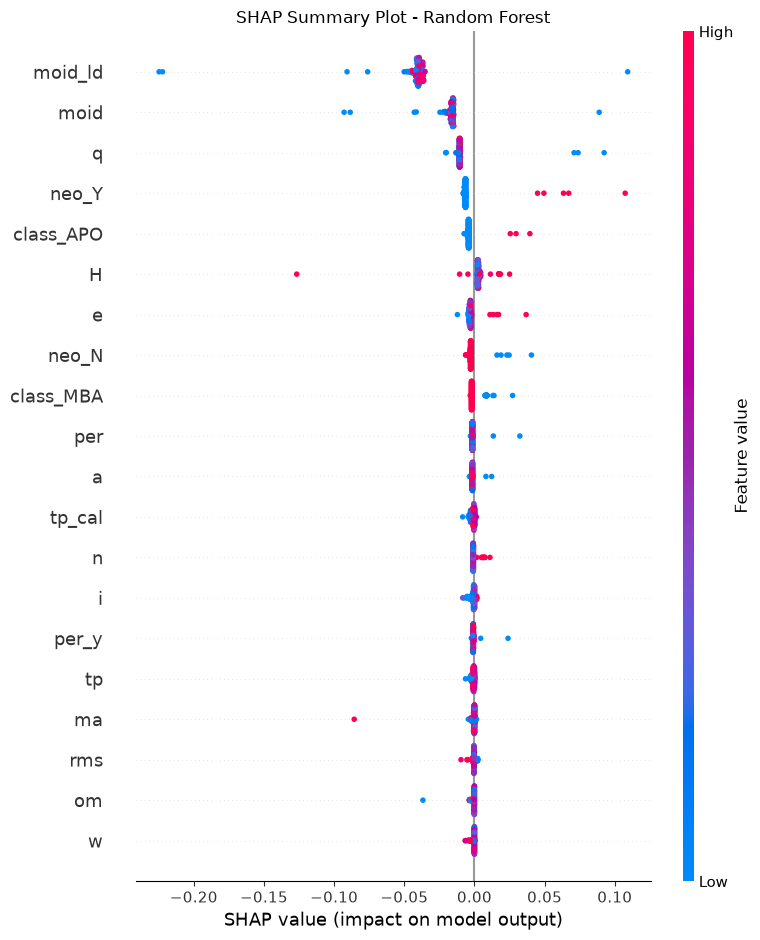

In [81]:
shap.summary_plot(
    shap_positive,
    X_shap,
    show=False
)

plt.title("SHAP Summary Plot - Random Forest")
plt.tight_layout()
plt.show()

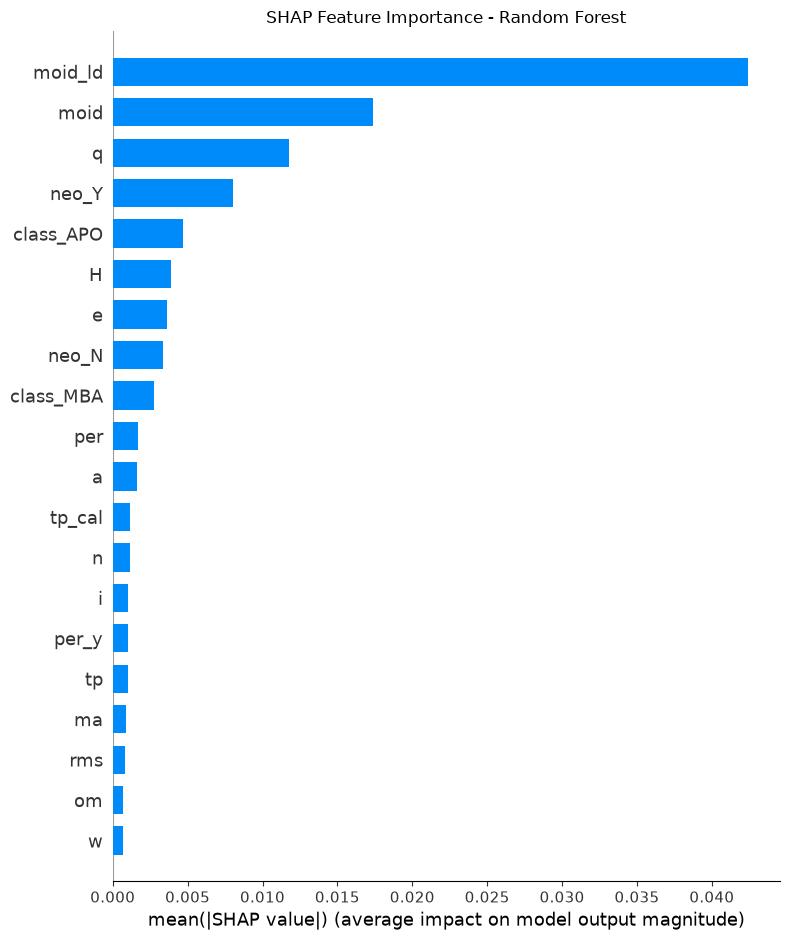

In [82]:
shap.summary_plot(
    shap_positive,
    X_shap,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


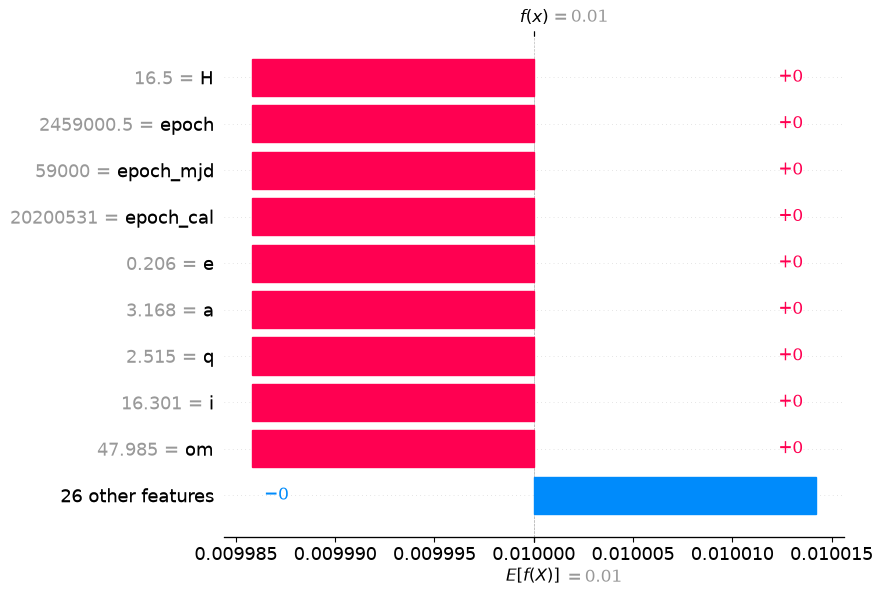

In [84]:
# Use the modern SHAP Explanation API
explainer_new = shap.Explainer(rf_model, X_shap)

individual_explanation = explainer_new(
    X_shap.iloc[[row_index]]
)

shap.plots.waterfall(
    individual_explanation[0, :, 1]
)

In [85]:
plt.figure()

shap.summary_plot(
    shap_positive,
    X_shap,
    plot_type="bar",
    show=False
)

plt.savefig(
    "shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close("all")

In [ ]:
#Load the existing Random Forest pipeline
run_id = "ee9add51f9cc4b3fb27431f79b393dfc"

final_pipeline = mlflow.sklearn.load_model(
    f"runs:/{run_id}/model"
)
print("Final pipeline loaded successfully!")
print(final_pipeline)

Final pipeline loaded successfully!
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('smote', SMOTE(random_state=42, sampling_strategy=0.1)),
                ('classifier',
                 RandomForestClassifier(min_samples_leaf=2, n_jobs=-1,
                                        random_state=42))])


In [ ]:
#Validate the pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Predict using the existing fitted pipeline
y_pred = final_pipeline.predict(X_test)
y_prob = final_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
final_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1_score": f1_score(y_test, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_prob),
    "average_precision": average_precision_score(y_test, y_prob)
}

print("Final model evaluation:")
for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-PHA", "PHA"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Final model evaluation:
accuracy: 0.9979
precision: 0.5205
recall: 0.7553
f1_score: 0.6163
roc_auc: 0.9988
average_precision: 0.7337

Classification Report:
              precision    recall  f1-score   support

     Non-PHA       1.00      1.00      1.00    186048
         PHA       0.52      0.76      0.62       421

    accuracy                           1.00    186469
   macro avg       0.76      0.88      0.81    186469
weighted avg       1.00      1.00      1.00    186469


Confusion Matrix:
[[185755    293]
 [   103    318]]


In [88]:
#Log final validation metrics to MLflow
with mlflow.start_run(run_name="RandomForest_Final_Validation"):
    mlflow.log_param("selected_model", "RandomForest")
    mlflow.log_param("source_run_id", run_id)
    mlflow.log_metrics(final_metrics)

    print("Final validation metrics logged to MLflow.")

Final validation metrics logged to MLflow.
🏃 View run RandomForest_Final_Validation at: http://localhost:5000/#/experiments/1/runs/28d3b0a6b94f4fe69411fed24d212144
🧪 View experiment at: http://localhost:5000/#/experiments/1


In [ ]:
#2.1 Register the existing model
import mlflow
model_name = "PHA_RandomForest_Classifier"
model_uri = f"runs:/{run_id}/model"

registered_model = mlflow.register_model(
    model_uri=model_uri,
    name=model_name
)

print("Model registered successfully!")
print("Model name:", registered_model.name)
print("Model version:", registered_model.version)

Registered model 'PHA_RandomForest_Classifier' already exists. Creating a new version of this model...
2026/10/17 18:24:09 WARNING mlflow.tracking._model_registry.fluent: Run with id ee9add51f9cc4b3fb27431f79b393dfc has no artifacts at artifact path 'model', registering model based on models:/m-77eec7d3c918411889c1615a9ab65cba instead
2026/10/17 18:24:09 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: PHA_RandomForest_Classifier, version 2
Created version '2' of model 'PHA_RandomForest_Classifier'.


Model registered successfully!
Model name: PHA_RandomForest_Classifier
Model version: 2


In [93]:
#Load the registered model
import mlflow.sklearn

model_version = registered_model.version

registered_pipeline = mlflow.sklearn.load_model(
    f"models:/{model_name}/{model_version}"
)

print("Registered model loaded successfully!")

Registered model loaded successfully!


In [ ]:
#Feature Configuration for streamlit

feature_config = []

for column in X_train.columns:
    values = pd.to_numeric(X_train[column], errors="coerce")
    median_value = values.median()

    if pd.isna(median_value):
        median_value = 0.0

    feature_config.append({
        "name": str(column),
        "default": float(median_value)
    })

with open("feature_config.json", "w") as f:
    json.dump(feature_config, f, indent=4)

print("feature_config.json created successfully!")

feature_config.json created successfully!
